In [16]:
from lire_fichiers import charger_donnees

donnees = charger_donnees()

# Affiche la liste des fichiers chargés et leurs dimensions
for nom, table in donnees.items():
    print(f"{nom} : {table.shape[0]} lignes, {table.shape[1]} colonnes")

# Manipule un fichier précis par son nom
premier_fichier = list(donnees.keys())[1]
df_1 = donnees[premier_fichier]
df_1.head()

decp-2024.parquet : 263037 lignes, 40 colonnes
decp-2025.parquet : 331165 lignes, 40 colonnes
decp-2026.parquet : 329312 lignes, 40 colonnes


,id,nature,objet,codeCPV,procedure,dureeMois,dateNotification,datePublicationDonnees,montant,formePrix,...,modificationsActesSousTraitance,idAccordCadre,modifications,dateSignature,dateDebutExecution,valeurGlobale,montantSubventionPublique,donneesExecution,concessionnaires,autoriteConcedante.id
0,2024-12 LOT 3,Marché,ASSURANCE VEHICULES A MOTEUR,66334100-1,Appel d'offres ouvert,48,2024-12-06,1920-04-25,83565.2,Forfaitaire,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,202502L01,Marché,Preparation et livraison de repas en liaison f...,55500000-5,Procédure adaptée,12,2025-07-31,2000-06-03,131296.0,Forfaitaire,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024TR07-11BIS,Marché,RESTRUCTURATION DE LA SALLE COMMUNALE ET POLYV...,40100000-3,Procédure adaptée,12,2025-03-04,2000-10-25,61200.0,Unitaire,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025 05 1,Marché,PRESTATION DE NETTOYAGE ECOLE VI,90910000-9,Procédure adaptée,24,2024-04-29,2003-03-06,40000.0,Unitaire,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,202401L03,Marché,Charpente bois,45214200-2,Procédure adaptée,17,2024-02-08,2003-11-24,49066.8,Unitaire,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
import pandas as pd

# 1. Calcul des valeurs manquantes sur l'ensemble des fichiers de 'donnees'
total_lignes = sum(len(table) for table in donnees.values())

valeurs_valides = pd.concat(
    [table.notna().sum() for table in donnees.values()], axis=1
).sum(axis=1)

bilan_nan = pd.DataFrame({
    "nb_nan": (total_lignes - valeurs_valides).astype(int),
    "pourcentage_nan": ((total_lignes - valeurs_valides) / total_lignes * 100).round(2),
}).sort_values(by="nb_nan", ascending=False)

# 2. Extraction des colonnes 100 % vides
colonnes_vides = list(bilan_nan[bilan_nan["pourcentage_nan"] == 100].index)
print(f"Colonnes complètement vides ({len(colonnes_vides)}) :", colonnes_vides)

# Affiche le tableau complet trié des colonnes les plus vides aux plus remplies
bilan_nan

Colonnes complètement vides (0) : []


,nb_nan,pourcentage_nan
donneesExecution,923008,99.95
concessionnaires,922539,99.89
montantSubventionPublique,922539,99.89
dateSignature,922539,99.89
autoriteConcedante.id,922539,99.89
valeurGlobale,922539,99.89
dateDebutExecution,922539,99.89
modificationsActesSousTraitance,893438,96.74
actesSousTraitance,832652,90.16
idAccordCadre,775182,83.94


In [18]:
import fsspec
import pyarrow.parquet as pq

URL_ENTREPRISES = (
    "https://minio.lab.sspcloud.fr/k1000ensae/diffusion/projet-2a/data/"
    "donnees_financieres_entreprises.parquet"
)

with fsspec.open(URL_ENTREPRISES, "rb") as f:
    pf = pq.ParquetFile(f)
    print("Colonnes exactes :", pf.schema_arrow.names)
    apercu = next(pf.iter_batches(batch_size=5)).to_pandas()

apercu

Colonnes exactes : ['siren', 'date_cloture_exercice', 'type_bilan', 'confidentiality', 'liasse']


,siren,date_cloture_exercice,type_bilan,confidentiality,liasse
0,005420120,2018-12-31,C,Public,"[(DJ, 1064), (DP, 48780), (FW, 385776), (LN, 5..."
1,005420120,2021-12-31,C,Public,"[(LS, 348019), (1A, 3546013), (AW, 0), (BB-BC,..."
2,005420120,2017-12-31,C,Public,"[(GM, 296672), (HH, 260060), (DA, 711840), (FH..."
3,005420120,2016-12-31,C,Public,"[(0G, 69830594), (BF-BG, 1760), (FS, 11836), (..."
4,005420120,2019-12-31,C,Public,"[(AS, 84588), (FD, 0), (FH, 0), (GP, 805059), ..."


In [19]:
import fsspec
import pyarrow.parquet as pq

URL_ENTREPRISES = (
    "https://minio.lab.sspcloud.fr/k1000ensae/diffusion/projet-2a/data/"
    "donnees_financieres_entreprises.parquet"
)

with fsspec.open(URL_ENTREPRISES, "rb") as f:
    pf = pq.ParquetFile(f)
    echantillon = next(pf.iter_batches(batch_size=1000)).to_pandas()

# Convertit la colonne liasse en vrais dictionnaires Python
echantillon["liasse"] = echantillon["liasse"].apply(dict)

# Garde uniquement les lignes dont la liasse n'est pas vide (bilans non confidentiels)
non_vides = echantillon[echantillon["liasse"].str.len() > 0]

print("Répartition des types de bilan :")
print(non_vides["type_bilan"].value_counts(), "\n")

# Affiche le contenu de la liasse pour le premier bilan complet ('C') et simplifié ('S')
for tb in ["C", "S"]:
    sous_ensemble = non_vides[non_vides["type_bilan"] == tb]
    if not sous_ensemble.empty:
        print(f"Exemple liasse type '{tb}' :", sous_ensemble["liasse"].iloc[0])

Répartition des types de bilan :
type_bilan
C    963
K     21
S     16
Name: count, dtype: int64 

Exemple liasse type 'C' : {'DJ': 1064, 'DP': 48780, 'FW': 385776, 'LN': 5850813, 'AJ': 540293, 'BI': 0, 'FD': 954, 'LS': 1503473, 'NK': 78273512, 'AP': 3174799, 'DQ': 2839131, 'DX': 148218, 'FE': 0, 'FY': 559989, 'HB': 209176, 'HI': 481014, 'QU': 2368581, 'AU': 196924, 'DB': 7963, 'CI': 0, 'CK': 2005218, 'CG': 0, 'CH': 36923, 'BB-BC': 9347425, 'CD-CE': 12917722, 'DD': 71183, 'EA': 123502, 'GG': -1281259, 'GJ': 39482, 'AN': 2288972, 'AT-AU': 47706, 'UC': 12390, 'GM': 58113, 'ØR': 2563605, 'CJ': 17122824, 'DG': 89549282, 'EC': 4341098, 'FL': 135797, 'AS': 80009, 'CA': 1703757, 'HG': 9499, 'LO': 0, 'BH-BI': 2559, 'CE': 301461, 'DI': -289131, 'FQ': 206166, 'HA': 280517, 'KE': 0, 'QW': 57930, 'AN-AO': 1888651, 'CF': 1404319, 'GK': 28079, '7C': 220031, 'FK': 0, 'HF': 111571, 'ØK': 82226, 'BZ-CA': 529304, 'GP': 745630, 'CO-1A': 97498351, 'CR': 1299000, 'PF': 27044, 'BV': 199270, 'CH-CI': 36923, 

In [20]:
URL_SIRET = (
    "https://minio.lab.sspcloud.fr/glemesre/diffusion/"
    "stock-stocketablissement-parquet.parquet"
)

with fsspec.open(URL_SIRET, "rb") as f:
    pf = pq.ParquetFile(f)
    print("Colonnes exactes :", pf.schema_arrow.names)
    apercu = next(pf.iter_batches(batch_size=5)).to_pandas()

apercu

Colonnes exactes : ['siren', 'nic', 'siret', 'statutDiffusionEtablissement', 'dateCreationEtablissement', 'trancheEffectifsEtablissement', 'anneeEffectifsEtablissement', 'activitePrincipaleRegistreMetiersEtablissement', 'dateDernierTraitementEtablissement', 'etablissementSiege', 'nombrePeriodesEtablissement', 'complementAdresseEtablissement', 'numeroVoieEtablissement', 'indiceRepetitionEtablissement', 'dernierNumeroVoieEtablissement', 'indiceRepetitionDernierNumeroVoieEtablissement', 'typeVoieEtablissement', 'libelleVoieEtablissement', 'codePostalEtablissement', 'libelleCommuneEtablissement', 'libelleCommuneEtrangerEtablissement', 'distributionSpecialeEtablissement', 'codeCommuneEtablissement', 'codeCedexEtablissement', 'libelleCedexEtablissement', 'codePaysEtrangerEtablissement', 'libellePaysEtrangerEtablissement', 'identifiantAdresseEtablissement', 'coordonneeLambertAbscisseEtablissement', 'coordonneeLambertOrdonneeEtablissement', 'complementAdresse2Etablissement', 'numeroVoie2Etabli

,siren,nic,siret,statutDiffusionEtablissement,dateCreationEtablissement,trancheEffectifsEtablissement,anneeEffectifsEtablissement,activitePrincipaleRegistreMetiersEtablissement,dateDernierTraitementEtablissement,etablissementSiege,...,dateDebut,etatAdministratifEtablissement,enseigne1Etablissement,enseigne2Etablissement,enseigne3Etablissement,denominationUsuelleEtablissement,activitePrincipaleEtablissement,nomenclatureActivitePrincipaleEtablissement,caractereEmployeurEtablissement,activitePrincipaleNAF25Etablissement
0,000325175,00016,00032517500016,O,2000-09-26,NN,NaN,3212ZZ,2024-03-22 15:40:57,False,...,2009-05-27,F,NaN,NaN,NaN,NaN,32.12Z,NAFRev2,N,NaN
1,000325175,00024,00032517500024,O,2008-05-20,NN,NaN,NaN,2024-03-30 05:08:28,False,...,2011-10-21,F,TAHITI PERLES CREATIONS,NaN,NaN,NaN,47.89Z,NAFRev2,N,NaN
2,000325175,00032,00032517500032,O,2009-05-27,NN,NaN,NaN,2024-03-30 05:56:39,False,...,2011-10-21,F,TAHITI PERLES CREATIONS,NaN,NaN,NaN,32.12Z,NAFRev2,N,NaN
3,000325175,00040,00032517500040,O,2011-10-21,NN,NaN,3212ZZ,2024-03-30 05:48:29,False,...,2014-01-07,F,TAHITI PERLES CREATION,NaN,NaN,NaN,32.12Z,NAFRev2,N,NaN
4,000325175,00057,00032517500057,O,2014-01-07,NN,NaN,NaN,2024-03-30 05:29:10,False,...,2018-02-07,F,TAHITI PERLES CREATION,NaN,NaN,NaN,32.12Z,NAFRev2,N,NaN


In [21]:
URL_ENTREPRISES = (
    "https://minio.lab.sspcloud.fr/glemesre/diffusion/"
    "ratios_inpi_bce(1).parquet"
)

with fsspec.open(URL_ENTREPRISES, "rb") as f:
    pf2 = pq.ParquetFile(f)
    print("Colonnes exactes :", pf2.schema_arrow.names)
    apercu = next(pf2.iter_batches(batch_size=5)).to_pandas()

apercu

Colonnes exactes : ['siren', 'date_cloture_exercice', 'chiffre_d_affaires', 'marge_brute', 'ebe', 'ebit', 'resultat_net', 'taux_d_endettement', 'ratio_de_liquidite', 'ratio_de_vetuste', 'autonomie_financiere', 'poids_bfr_exploitation_sur_ca', 'couverture_des_interets', 'caf_sur_ca', 'capacite_de_remboursement', 'marge_ebe', 'resultat_courant_avant_impots_sur_ca', 'poids_bfr_exploitation_sur_ca_jours', 'rotation_des_stocks_jours', 'credit_clients_jours', 'credit_fournisseurs_jours', 'type_bilan', 'confidentiality']


,siren,date_cloture_exercice,chiffre_d_affaires,marge_brute,ebe,ebit,resultat_net,taux_d_endettement,ratio_de_liquidite,ratio_de_vetuste,...,caf_sur_ca,capacite_de_remboursement,marge_ebe,resultat_courant_avant_impots_sur_ca,poids_bfr_exploitation_sur_ca_jours,rotation_des_stocks_jours,credit_clients_jours,credit_fournisseurs_jours,type_bilan,confidentiality
0,844516393,2023-12-31,0,0,-8233,-8233,752563,0.245,191.170,NaN,...,NaN,0.000,NaN,NaN,NaN,NaN,NaN,452.860,S,Public
1,844517946,2024-12-31,492542,492542,-1048336,-1059966,18937725,0.000,700.330,97.494,...,-210.560,0.000,-212.842,-148.487,-305.397,0.000,0.000,4.709,C,Public
2,844518340,2020-12-31,0,0,0,0,52453,3.642,117.672,67.808,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,C,Partiellement confidentiel
3,844518951,2020-09-30,2288570,1609290,47457,22162,15416,437.993,163.741,84.520,...,0.847,26.827,2.074,0.970,206.002,17.762,81.238,104.217,C,Public
4,844519330,2019-12-31,0,0,-2439,-2439,-2448,0.211,0.043,NaN,...,NaN,-0.453,NaN,NaN,NaN,NaN,NaN,287.823,C,Public


In [22]:
# %%
import gc
import numpy as np
import pandas as pd
import fsspec
import pyarrow.parquet as pq

# ==============================================================================
# 1. CONSOLIDATION ET NETTOYAGE DES DECP (depuis le dictionnaire `donnees`)
# ==============================================================================

df_decp_raw = pd.concat(donnees.values(), ignore_index=True)

# Suppression des colonnes 100 % vides (y'en a pas mais bon)
df_decp_raw = df_decp_raw.drop(columns=colonnes_vides, errors="ignore")
#Remplace les noms de variables avec "." en "_"
df_decp_raw.columns = df_decp_raw.columns.str.replace(".", "_", regex=False)


def clean_decp(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    id_col = "uid" if "uid" in df.columns else "id"
    cols_keep = [
        c for c in [
            id_col, "id", "nature", "procedure", "codeCPV",
            "montant", "dureeMois", "dateNotification",
            "acheteur_id", "acheteur_nom",
            "lieuExecution_code", "lieuExecution_typeCode",
            "titulaires",
        ] if c in df.columns
    ]
    df = df[list(dict.fromkeys(cols_keep))]

    # Conversion des types
    df["montant"] = pd.to_numeric(df["montant"], errors="coerce")
    df["dureeMois"] = pd.to_numeric(df["dureeMois"], errors="coerce")
    df["dateNotification"] = pd.to_datetime(df["dateNotification"], errors="coerce")

    # Conservation des marchés ayant au moins un titulaire (gère list et np.ndarray)
    has_tit = df["titulaires"].apply(
        lambda x: isinstance(x, (list, np.ndarray)) and len(x) > 0
    )
    df = df[has_tit].copy()

    # Répartition équitable du montant entre co-titulaires d'un groupement
    df["nb_titulaires"] = df["titulaires"].apply(len)
    df["montant_part"] = df["montant"] / df["nb_titulaires"]

    # Aplatissement : 1 ligne par couple (marché, titulaire)
    df = df.explode("titulaires").reset_index(drop=True)

    tit_records = [
        t["titulaire"] if isinstance(t, dict) and "titulaire" in t
        else (t if isinstance(t, dict) else {})
        for t in df["titulaires"]
    ]
    df_tit = pd.json_normalize(tit_records).rename(columns={
        "id": "titulaire_id",
        "typeIdentifiant": "titulaire_type_id",
        "denominationSociale": "titulaire_nom",
    })

    cols_tit = [c for c in ["titulaire_id", "titulaire_type_id", "titulaire_nom"] if c in df_tit.columns]
    df = pd.concat([df.drop(columns=["titulaires"]), df_tit[cols_tit]], axis=1)

    # Normalisation du SIRET (14 chiffres) et extraction du SIREN (9 chiffres)
    df["titulaire_id"] = df["titulaire_id"].astype(str).str.strip()
    is_siret = (df["titulaire_type_id"] == "SIRET") & (df["titulaire_id"].str.match(r"^\d{14}$"))
    print(f"Part de lignes avec SIRET valide (14 chiffres) : {is_siret.mean():.1%}")

    df = df[is_siret].copy()
    df["siret"] = df["titulaire_id"]
    df["siren"] = df["siret"].str[:9]

    # Suppression des doublons de publication sur un même couple (marché, siret)
    avant_dedup = len(df)
    df = df.drop_duplicates(subset=[id_col, "siret"]).copy()
    print(f"Doublons (marché, siret) supprimés : {avant_dedup - len(df):,}")

    # Filtrage des valeurs aberrantes (accords-cadres saisis à 1 € ou erreurs > 500 M€)
    avant_filt = len(df)
    df = df[(df["montant_part"] > 100) & (df["montant_part"] < 5e8)].copy()
    print(f"Lignes écartées pour montant aberrant (<= 100 € ou >= 500 M€) : {avant_filt - len(df):,}")

    # Montant annualisé pour comparer équitablement contrats courts et pluriannuels
    duree_valide = df["dureeMois"].where(df["dureeMois"] > 0, np.nan)
    df["montant_annualise"] = df["montant_part"] / duree_valide * 12

    if "codeCPV" in df.columns:
        df["cpv_division"] = df["codeCPV"].astype(str).str.slice(0, 2)

    return df


df_decp = clean_decp(df_decp_raw)
del df_decp_raw
gc.collect()
print(f"DECP nettoyées prêtes pour la jointure : {len(df_decp):,} lignes")

Part de lignes avec SIRET valide (14 chiffres) : 98.9%
Doublons (marché, siret) supprimés : 218,785
Lignes écartées pour montant aberrant (<= 100 € ou >= 500 M€) : 4,091
DECP nettoyées prêtes pour la jointure : 841,697 lignes


In [23]:
# %%
# ==============================================================================
# 2. CHARGEMENT SÉLECTIF ET NETTOYAGE DE SIRENE (StockEtablissement)
# ==============================================================================

def map_naf_section(code_naf: pd.Series) -> pd.Series:
    """Regroupe les codes NAF Rev. 2 (ex: '41.20A') en 21 sections officielles (A à U)."""
    div = pd.to_numeric(code_naf.astype(str).str.slice(0, 2), errors="coerce")

    conditions = [
        div.between(1, 3),
        div.between(5, 9),
        div.between(10, 33),
        div == 35,
        div.between(36, 39),
        div.between(41, 43),
        div.between(45, 47),
        div.between(49, 53),
        div.between(55, 56),
        div.between(58, 63),
        div.between(64, 66),
        div == 68,
        div.between(69, 75),
        div.between(77, 82),
        div == 84,
        div == 85,
        div.between(86, 88),
        div.between(90, 93),
        div.between(94, 96),
        div.between(97, 98),
        div == 99,
    ]
    labels = [
        "A - Agriculture, sylviculture et pêche",
        "B - Industries extractives",
        "C - Industrie manufacturière",
        "D - Électricité, gaz, vapeur et air conditionné",
        "E - Eau, assainissement et déchets",
        "F - Construction (BTP)",
        "G - Commerce et réparation auto",
        "H - Transports et entreposage",
        "I - Hébergement et restauration",
        "J - Information et communication",
        "K - Activités financières et d'assurance",
        "L - Activités immobilières",
        "M - Activités spécialisées, scientifiques et techniques",
        "N - Services administratifs et de soutien",
        "O - Administration publique",
        "P - Enseignement",
        "Q - Santé humaine et action sociale",
        "R - Arts, spectacles et loisirs",
        "S - Autres activités de services",
        "T - Activités des ménages employeurs",
        "U - Organisations extraterritoriales",
    ]
    return pd.Series(np.select(conditions, labels, default="Inconnu"), index=code_naf.index)


cols_siret_cibles = [
    "siret",
    "siren",
    "etablissementSiege",
    "activitePrincipaleEtablissement",
    "nomenclatureActivitePrincipaleEtablissement",
    "trancheEffectifsEtablissement",
    "codeCommuneEtablissement",
    "etatAdministratifEtablissement",
]

with fsspec.open(URL_SIRET, "rb") as f:
    pf = pq.ParquetFile(f)
    cols_dispo = [c for c in cols_siret_cibles if c in pf.schema_arrow.names]
    df_sirene = pf.read(columns=cols_dispo).to_pandas()

# Normalisation de la clé SIRET (14 caractères) et unicité garantie
df_sirene["siret"] = df_sirene["siret"].astype(str).str.strip().str.zfill(14)
df_sirene = df_sirene.drop_duplicates(subset=["siret"]).copy()

# Création des variables sectorielles et géographiques
df_sirene["naf_code"] = df_sirene["activitePrincipaleEtablissement"].astype(str).str.strip()
df_sirene["naf_division"] = df_sirene["naf_code"].str.slice(0, 2)
df_sirene["naf_section"] = map_naf_section(df_sirene["naf_code"])

if "codeCommuneEtablissement" in df_sirene.columns:
    commune = df_sirene["codeCommuneEtablissement"].astype(str).str.strip()
    df_sirene["dep_titulaire"] = np.where(
        commune.str.startswith(("97", "98")),
        commune.str.slice(0, 3),
        commune.str.slice(0, 2),
    )

# Table de référence du poids économique réel de chaque secteur (sur les établissements actifs)
# À conserver pour calculer ensuite l'indice de surreprésentation dans la commande publique !
ref_secteurs_sirene = (
    df_sirene[df_sirene["etatAdministratifEtablissement"] == "A"]
    .groupby("naf_section", as_index=False)
    .agg(
        nb_etablissements_actifs=("siret", "count"),
        nb_entreprises_actives=("siren", "nunique"),
    )
)
ref_secteurs_sirene["part_etablissements_sirene"] = (
    ref_secteurs_sirene["nb_etablissements_actifs"]
    / ref_secteurs_sirene["nb_etablissements_actifs"].sum()
)

print(f"Sirene nettoyé : {len(df_sirene):,} établissements uniques")

Sirene nettoyé : 44,503,711 établissements uniques


In [24]:
# %%
# ==============================================================================
# 3. JOINTURE SÉCURISÉE (DECP x SIRENE) ET CONTRÔLE D'APPARIEMENT
# ==============================================================================

df_final = pd.merge(
    df_decp,
    df_sirene,
    on="siret",
    how="left",
    suffixes=("", "_sirene"),
    validate="many_to_one",
)

# Libération de la mémoire de la table Sirene complète
del df_sirene
gc.collect()

# Bilan de la qualité d'appariement
taux_lignes = df_final["naf_code"].notna().mean()
montant_tot = df_final["montant_part"].sum()
montant_ok = df_final.loc[df_final["naf_code"].notna(), "montant_part"].sum()

print(f"Nombre final de lignes (marché x titulaire) : {len(df_final):,}")
print(f"Taux d'appariement Sirene (en lignes)  : {taux_lignes:.1%}")
print(f"Taux d'appariement Sirene (en montant) : {montant_ok / montant_tot:.1%}")

# Sauvegarde intermédiaire pour ne pas recharger Sirene à chaque ouverture du notebook
df_final.to_parquet("decp_sirene_clean.parquet", index=False)
ref_secteurs_sirene.to_parquet("ref_secteurs_sirene.parquet", index=False)

# Aperçu des 10 premières sections NAF avec indice de surreprésentation
synthese = (
    df_final.groupby("naf_section", as_index=False)
    .agg(
        nb_contrats=("siret", "count"),
        nb_entreprises=("siren", "nunique"),
        montant_total_M=("montant_part", lambda s: s.sum() / 1e6),
        montant_median=("montant_part", "median"),
    )
    .merge(ref_secteurs_sirene, on="naf_section", how="left")
)
synthese["part_montant_decp"] = synthese["montant_total_M"] / synthese["montant_total_M"].sum()
synthese["indice_surrepresentation"] = (
    synthese["part_montant_decp"] / synthese["part_etablissements_sirene"]
)

synthese.sort_values("montant_total_M", ascending=False).head(10)

Nombre final de lignes (marché x titulaire) : 841,697
Taux d'appariement Sirene (en lignes)  : 99.7%
Taux d'appariement Sirene (en montant) : 99.6%


,naf_section,nb_contrats,nb_entreprises,montant_total_M,montant_median,nb_etablissements_actifs,nb_entreprises_actives,part_etablissements_sirene,part_montant_decp,indice_surrepresentation
5,F - Construction (BTP),315955,31441,219499.507152,134938.0,1028103,987764,0.060756,0.274129,4.511950
6,G - Commerce et réparation auto,111106,11720,150174.107954,100500.0,1873286,1677375,0.110703,0.187550,1.694175
13,"M - Activités spécialisées, scientifiques et t...",158768,25786,81815.685535,63242.5,1582965,1509499,0.093546,0.102178,1.092277
10,J - Information et communication,26242,4670,70614.438522,150000.0,499910,479438,0.029542,0.088189,2.985170
14,N - Services administratifs et de soutien,55032,7672,60417.993852,128000.0,977605,934798,0.057772,0.075455,1.306081
2,C - Industrie manufacturière,57250,7893,48051.428310,112000.0,477922,443194,0.028243,0.060011,2.124793
3,"D - Électricité, gaz, vapeur et air conditionné",9915,288,38255.818142,420000.0,258113,164859,0.015253,0.047777,3.132240
4,"E - Eau, assainissement et déchets",18359,1694,33935.387319,200000.0,47561,36512,0.002811,0.042381,15.078884
16,P - Enseignement,9631,2680,26557.239730,100000.0,547231,491940,0.032339,0.033167,1.025604
7,H - Transports et entreposage,16178,2685,25472.750096,200000.0,536370,497830,0.031697,0.031812,1.003642


In [25]:
df_final.head()

,id,nature,procedure,codeCPV,montant,dureeMois,dateNotification,acheteur_id,lieuExecution_code,lieuExecution_typeCode,...,etablissementSiege,activitePrincipaleEtablissement,nomenclatureActivitePrincipaleEtablissement,trancheEffectifsEtablissement,codeCommuneEtablissement,etatAdministratifEtablissement,naf_code,naf_division,naf_section,dep_titulaire
0,202401L03,Marché,Procédure adaptée,45214200-2,49066.80,17,2024-02-08,21030042200016,03120,Code postal,...,True,43.91A,NAFRev2,03,03131,A,43.91A,43,F - Construction (BTP),03
1,2024/1111,Marché,Procédure adaptée,55523100-3,350000.00,48,2024-07-11,20000017200011,74130,Code postal,...,True,56.29A,NAFRev2,21,74224,A,56.29A,56,I - Hébergement et restauration,74
2,202402L12,Marché de partenariat,Procédure adaptée,45112500-0,112230.57,14,2024-05-14,21070260100019,07210,Code postal,...,False,43.12A,NAFRev2,00,07219,F,43.12A,43,F - Construction (BTP),07
3,20189570000000,Marché,Procédure avec négociation,48900000-7,150000.00,96,2018-05-28,13000222300027,FR,Code pays,...,True,62.02B,NAFRev2,22,92060,F,62.02B,62,J - Information et communication,92
4,201808/201818,Marché,Appel d'offres ouvert,45112710-5,217241.03,18,2018-06-28,21740042300018,BONNE,Code postal,...,False,81.30Z,NAFRev2,12,74112,A,81.30Z,81,N - Services administratifs et de soutien,74


In [26]:
import requests
import pandas as pd
import plotly.express as px

# 1. Load official French départements GeoJSON directly from GitHub (gregoiredavid/france-geojson)
geojson_url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
departements_geo = requests.get(geojson_url).json()

# 2. Aggregate your data by dep_titulaire
# Keep only matched rows (where siren_sirene is not null)
df_matched = df_final[df_final["siren_sirene"].notna()].copy()

dep_stats = (
    df_matched.groupby("dep_titulaire", as_index=False)
    .agg(
        nb_marches=("id", "nunique"),
        montant_total=("montant_part", "sum"),
        montant_median=("montant_part", "median"),
    )
)

# Optional: Convert total amount to millions of euros for cleaner legend labels
dep_stats["montant_millions"] = dep_stats["montant_total"] / 1e6

# 3. Plot the choropleth map
fig = px.choropleth(
    dep_stats,
    geojson=departements_geo,
    locations="dep_titulaire",
    featureidkey="properties.code",  # Matches GeoJSON 'code' ("01", "2A", "75"...) to dep_titulaire
    color="montant_millions",         # Swap to "nb_marches" for contract count
    hover_name="dep_titulaire",
    hover_data={"nb_marches": True, "montant_millions": ":.1f"},
    color_continuous_scale="Viridis",
    labels={"montant_millions": "Montant attribué (M€)", "nb_marches": "Nombre de marchés"},
    title="Montant des marchés publics par département de l'établissement titulaire"
)

fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(margin={"r": 0, "t": 40, "l": 0, "b": 0})
fig.show()

/tmp/ipykernel_46458/719886477.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


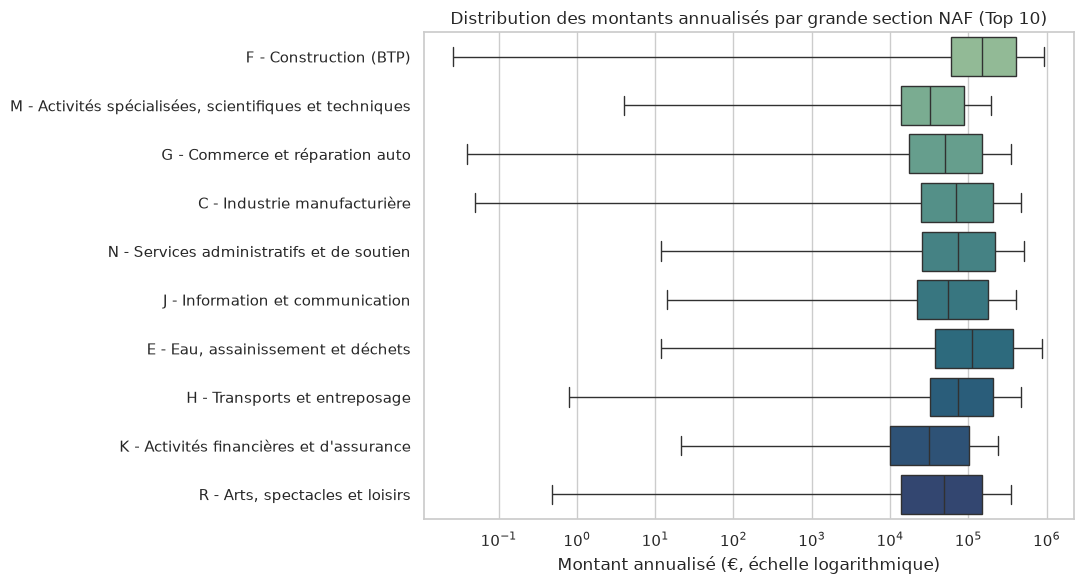

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filter positive amounts and top 10 NAF sections by contract count
top_sections = df_final["naf_section"].value_counts().nlargest(10).index
df_plot = df_final[
    (df_final["naf_section"].isin(top_sections)) & (df_final["montant_annualise"] > 0)
]

plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df_plot,
    x="montant_annualise",
    y="naf_section",
    order=top_sections,
    palette="crest",
    showfliers=False  # Hides extreme dots so the interquartile boxes stay readable
)
plt.xscale("log")
plt.xlabel("Montant annualisé (€, échelle logarithmique)")
plt.ylabel("")
plt.title("Distribution des montants annualisés par grande section NAF (Top 10)")
plt.tight_layout()
plt.show()

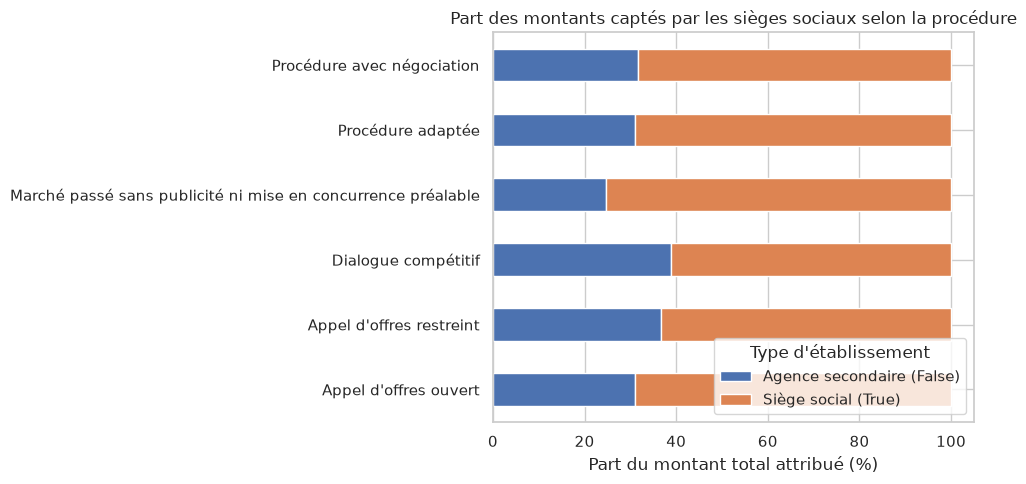

In [28]:
# Map INSEE employee codes to readable labels
effectif_labels = {
    "NN": "0 salarié / Non renseigné", "00": "0 salarié",
    "01": "1-2 sal.", "02": "3-5 sal.", "03": "6-9 sal.",
    "11": "10-19 sal.", "12": "20-49 sal.", "21": "50-99 sal.",
    "22": "100-199 sal.", "31": "200-249 sal.", "32": "250-499 sal.",
    "41": "500-999 sal.", "42": "1000-1999 sal.", "51": "2000-4999 sal.", "52": "5000+ sal."
}
df_matched["taille_etab"] = df_matched["trancheEffectifsEtablissement"].map(effectif_labels)

# Compare share of contract VOLUME (€) vs. share of contract COUNT by procedure
ct_volume = pd.crosstab(
    df_matched["procedure"],
    df_matched["etablissementSiege"],
    values=df_matched["montant_part"],
    aggfunc="sum",
    normalize="index"
) * 100

ax = ct_volume.plot(kind="barh", stacked=True, figsize=(10, 5), color=["#4c72b0", "#dd8452"])
ax.set_xlabel("Part du montant total attribué (%)")
ax.set_ylabel("")
ax.legend(["Agence secondaire (False)", "Siège social (True)"], title="Type d'établissement", loc="lower right")
ax.set_title("Part des montants captés par les sièges sociaux selon la procédure")
plt.tight_layout()
plt.show()

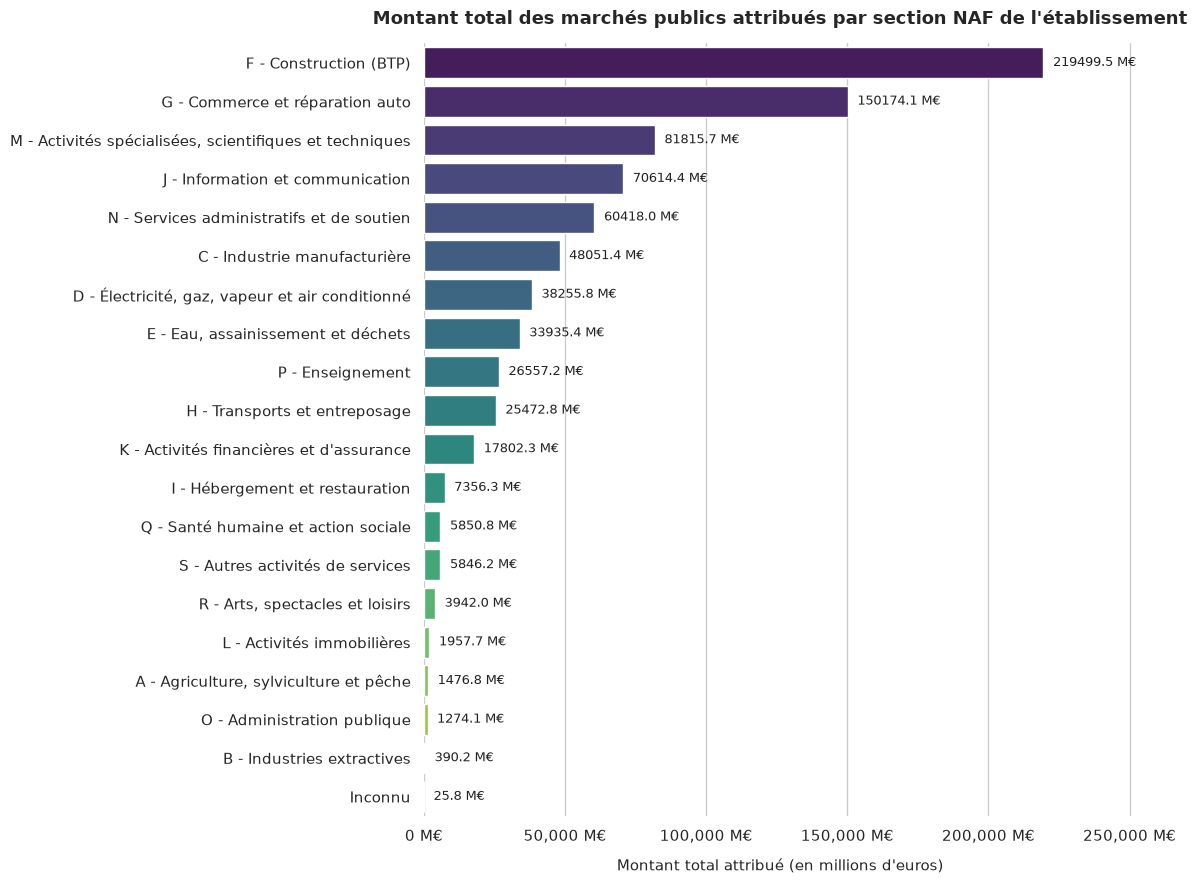

Chart saved! Plotted 20 NAF sections.


In [29]:
import matplotlib.ticker as ticker


# 1. Keep valid Sirene matches with positive contract amounts
df_valid = df_final[
    df_final["siren_sirene"].notna()
    & df_final["naf_section"].notna()
    & (df_final["montant_part"] > 0)
].copy()

# 2. Aggregate total money acquired (in millions of €) and contract count for ALL NAF sections
sector_totals = (
    df_valid.groupby("naf_section", observed=True, as_index=False)
    .agg(
        montant_total=("montant_part", "sum"),
        nb_marches=("id", "nunique"),
    )
    .sort_values("montant_total", ascending=False)
)

sector_totals["montant_millions"] = sector_totals["montant_total"] / 1e6

# 3. Plot all NAF sections dynamically (figure height scales with number of sectors)
sns.set_theme(style="whitegrid")
fig_height = max(7, len(sector_totals) * 0.45)
fig, ax = plt.subplots(figsize=(12, fig_height))

sns.barplot(
    data=sector_totals,
    x="montant_millions",
    y="naf_section",
    palette="viridis",
    hue="naf_section",
    legend=False,
    ax=ax,
)

# 4. Add direct value labels at the end of each bar so small sectors remain readable
max_val = sector_totals["montant_millions"].max()
for container in ax.containers:
    ax.bar_label(
        container,
        fmt=" %.1f M€",
        padding=4,
        fontsize=9,
        color="#222222",
    )

# Give extra space on the right so labels on the longest bar don't get clipped
ax.set_xlim(0, max_val * 1.15)
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f} M€"))

ax.set_xlabel("Montant total attribué (en millions d'euros)", fontsize=11, labelpad=10)
ax.set_ylabel("")
ax.set_title(
    "Montant total des marchés publics attribués par section NAF de l'établissement",
    fontsize=13,
    fontweight="bold",
    pad=14,
)

sns.despine(left=True, bottom=True)
plt.tight_layout()

# Save to disk (or replace with plt.show() if working in a Jupyter notebook)
plt.show()

print(f"Chart saved! Plotted {len(sector_totals)} NAF sections.")

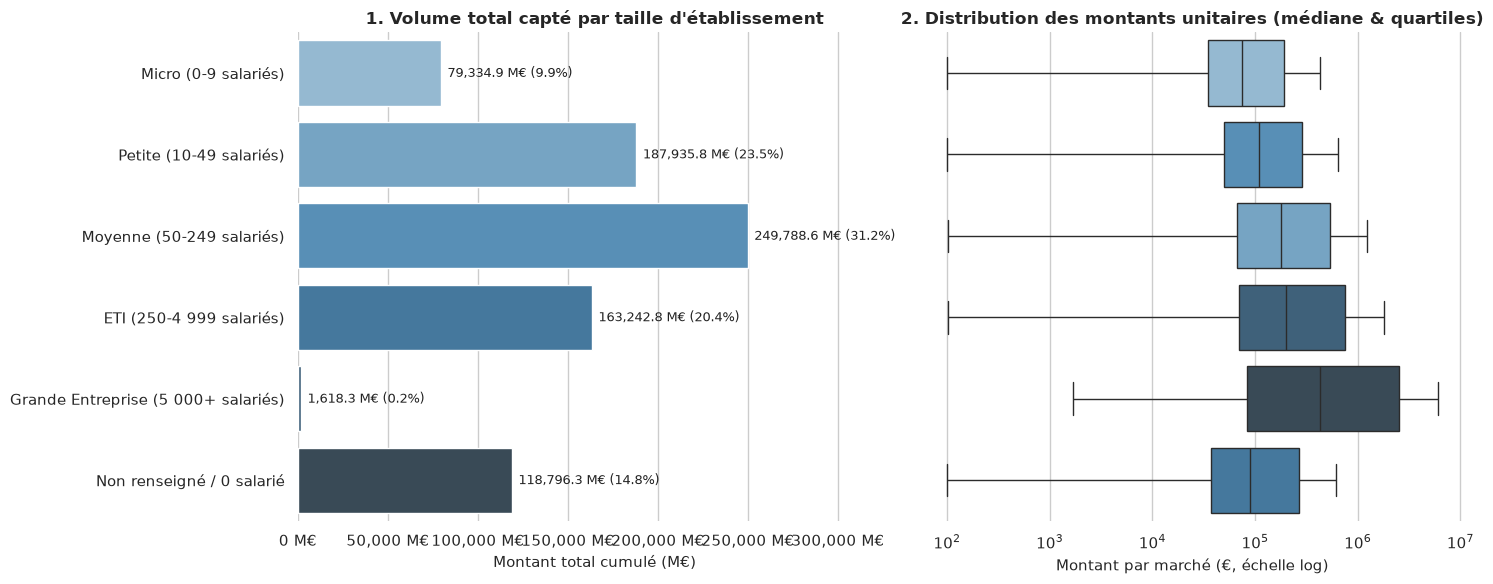

In [32]:
# 1. Map INSEE trancheEffectifsEtablissement codes to standard French firm-size categories
# Note: trancheEffectifsEtablissement measures establishment headcount (a proxy for firm size)
size_mapping = {
    "NN": "Non renseigné / 0 salarié",
    "00": "Micro (0-9 salariés)",
    "01": "Micro (0-9 salariés)",
    "02": "Micro (0-9 salariés)",
    "03": "Micro (0-9 salariés)",
    "11": "Petite (10-49 salariés)",
    "12": "Petite (10-49 salariés)",
    "21": "Moyenne (50-249 salariés)",
    "22": "Moyenne (50-249 salariés)",
    "31": "Moyenne (50-249 salariés)",
    "32": "ETI (250-4 999 salariés)",
    "41": "ETI (250-4 999 salariés)",
    "42": "ETI (250-4 999 salariés)",
    "51": "ETI (250-4 999 salariés)",
    "52": "Grande Entreprise (5 000+ salariés)",
    "53": "Grande Entreprise (5 000+ salariés)"
}

category_order = [
    "Micro (0-9 salariés)",
    "Petite (10-49 salariés)",
    "Moyenne (50-249 salariés)",
    "ETI (250-4 999 salariés)",
    "Grande Entreprise (5 000+ salariés)",
    "Non renseigné / 0 salarié",
]

# 2. Filter valid Sirene matches with positive contract amounts
df_size = df_final[
    df_final["siren_sirene"].notna() & (df_final["montant_part"] > 0)
].copy()

df_size["categorie_taille"] = (
    df_size["trancheEffectifsEtablissement"]
    .fillna("NN")
    .map(size_mapping)
    .fillna("Non renseigné / 0 salarié")
)

# 3. Aggregate total amount and contract count by size category
agg_size = (
    df_size.groupby("categorie_taille", observed=False)
    .agg(
        montant_total=("montant_part", "sum"),
        nb_marches=("id", "nunique"),
        montant_median=("montant_part", "median"),
    )
    .reindex(category_order, fill_value=0)
    .reset_index()
)

agg_size["montant_millions"] = agg_size["montant_total"] / 1e6
agg_size["part_volume_pct"] = (
    agg_size["montant_total"] / agg_size["montant_total"].sum() * 100
)

# 4. Plot: Left = Aggregate Volume (Bar) | Right = Contract Size Distribution (Boxplot)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.1, 1]})

# --- Panel 1: Aggregate Amount Acquired ---
sns.barplot(
    data=agg_size,
    x="montant_millions",
    y="categorie_taille",
    palette="Blues_d",
    hue="categorie_taille",
    legend=False,
    ax=axes[0],
)

max_m = agg_size["montant_millions"].max()
for idx, row in agg_size.iterrows():
    axes[0].text(
        row["montant_millions"] + max_m * 0.015,
        idx,
        f"{row['montant_millions']:,.1f} M€ ({row['part_volume_pct']:.1f}%)",
        va="center",
        fontsize=9.5,
        color="#222222",
    )

axes[0].set_xlim(0, max_m * 1.32)
axes[0].xaxis.set_major_formatter("{x:,.0f} M€")
axes[0].set_xlabel("Montant total cumulé (M€)", fontsize=11)
axes[0].set_ylabel("")
axes[0].set_title("1. Volume total capté par taille d'établissement", fontsize=12, fontweight="bold")

# --- Panel 2: Distribution of Individual Contract Amounts (Log Scale) ---
sns.boxplot(
    data=df_size,
    x="montant_part",
    y="categorie_taille",
    order=category_order,
    palette="Blues_d",
    hue="categorie_taille",
    legend=False,
    showfliers=False,
    ax=axes[1],
)

axes[1].set_xscale("log")
axes[1].set_xlabel("Montant par marché (€, échelle log)", fontsize=11)
axes[1].set_ylabel("")
axes[1].set_yticklabels([])  # Share Y-axis labels cleanly with the left panel
axes[1].set_title("2. Distribution des montants unitaires (médiane & quartiles)", fontsize=12, fontweight="bold")

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

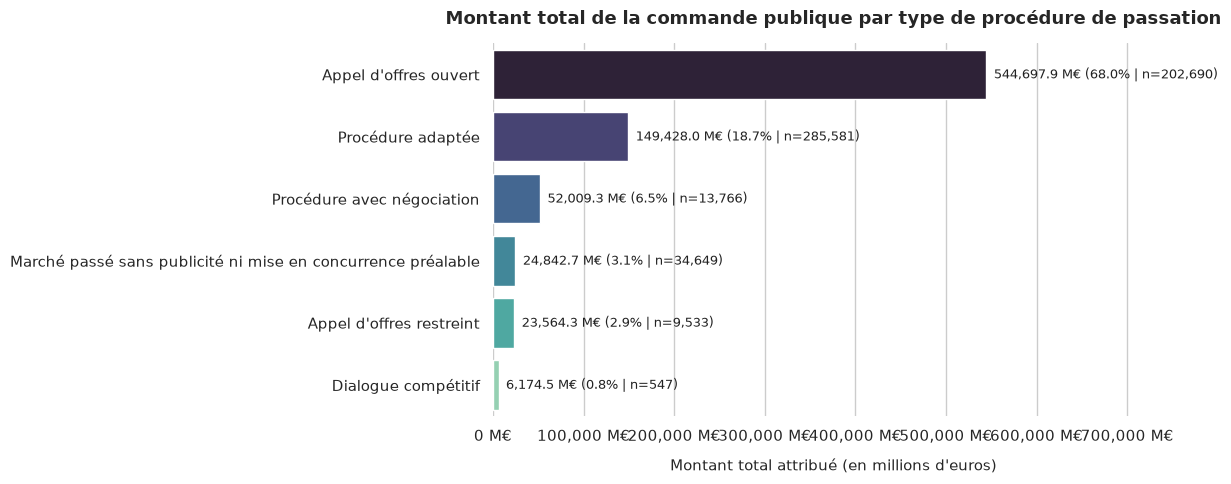

In [33]:
# 1. Prepare clean dataset
df_proc = df_final[
    df_final["siren_sirene"].notna()
    & df_final["procedure"].notna()
    & (df_final["montant_part"] > 0)
].copy()

# 2. Aggregate total amount paid and distinct contract count by procedure
proc_agg = (
    df_proc.groupby("procedure", as_index=False)
    .agg(
        montant_total=("montant_part", "sum"),
        nb_marches=("id", "nunique"),
        montant_median=("montant_part", "median"),
    )
    .sort_values("montant_total", ascending=False)
    .reset_index(drop=True)
)

proc_agg["montant_millions"] = proc_agg["montant_total"] / 1e6
proc_agg["part_volume_pct"] = (
    proc_agg["montant_total"] / proc_agg["montant_total"].sum() * 100
)

# 3. Plot horizontal bar chart
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, max(5, len(proc_agg) * 0.55)))

sns.barplot(
    data=proc_agg,
    x="montant_millions",
    y="procedure",
    palette="mako",
    hue="procedure",
    legend=False,
    ax=ax,
)

# Annotate each bar with M€, % share of total spending, and contract count
max_val = proc_agg["montant_millions"].max()
for idx, row in proc_agg.iterrows():
    ax.text(
        row["montant_millions"] + max_val * 0.015,
        idx,
        f"{row['montant_millions']:,.1f} M€ ({row['part_volume_pct']:.1f}% | n={row['nb_marches']:,})",
        va="center",
        fontsize=9.5,
        color="#222222",
    )

ax.set_xlim(0, max_val * 1.38)
ax.xaxis.set_major_formatter("{x:,.0f} M€")
ax.set_xlabel("Montant total attribué (en millions d'euros)", fontsize=11, labelpad=10)
ax.set_ylabel("")
ax.set_title(
    "Montant total de la commande publique par type de procédure de passation",
    fontsize=13,
    fontweight="bold",
    pad=14,
)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

In [1]:
df_proc["categorie_taille"] = (
    df_proc["trancheEffectifsEtablissement"]
    .fillna("NN")
    .map(size_mapping)
    .fillna("Non renseigné / Non employeur")
)

# Order procedures from largest total spending to smallest (consistent with Plot 1)
proc_order = proc_agg["procedure"].tolist()

# 2. Compute 100% normalized cross-tabulations: (A) by contract count, (B) by euro volume
ct_count = (
    pd.crosstab(df_proc["procedure"], df_proc["categorie_taille"], normalize="index")
    .reindex(index=proc_order, columns=category_order, fill_value=0)
    * 100
)

ct_volume = (
    pd.crosstab(
        df_proc["procedure"],
        df_proc["categorie_taille"],
        values=df_proc["montant_part"],
        aggfunc="sum",
        normalize="index",
    )
    .reindex(index=proc_order, columns=category_order, fill_value=0)
    * 100
)

# 3. Plot side-by-side 100% stacked horizontal bars
sns.set_theme(style="whitegrid")
colors = ["#2b5c8f", "#4c8cb5", "#7fb3d5", "#f39c12", "#d35400", "#bdc3c7"]

fig, axes = plt.subplots(1, 2, figsize=(16, max(5.5, len(proc_order) * 0.6)), sharey=True)

# Left panel: Share of number of contracts
ct_count.plot(kind="barh", stacked=True, color=colors, width=0.72, ax=axes[0], legend=False)
axes[0].set_title("A. Répartition en NOMBRE de marchés (%)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Part des attributions (%)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 100)

# Right panel: Share of total euro volume
ct_volume.plot(kind="barh", stacked=True, color=colors, width=0.72, ax=axes[1], legend=False)
axes[1].set_title("B. Répartition en VOLUME financier (% des €)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Part des montants attribués (%)")
axes[1].set_xlim(0, 100)

# Add percentage labels inside segments wide enough to read (>= 8%)
for ax in axes:
    ax.invert_yaxis()  # Keep highest-volume procedure at the top
    for container in ax.containers:
        labels = [f"{v:.0f}%" if v >= 8 else "" for v in container.datavalues]
        ax.bar_label(container, labels=labels, label_type="center", color="white", fontsize=8.5, fontweight="bold")

# Single shared legend at the top
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.05),
    ncol=6,
    frameon=False,
    fontsize=9.5,
)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

NameError: name 'df_proc' is not defined